# Manual Day — Convolutions & Galaxy Classification

Closed-agent, ~60 min. Complete every `# FILL IN` cell, then run the check.

**Two problems. Work in order, as many as time permits.**

## Mini-lecture: convolutional networks

### Why not a dense network?

A dense network can approximate anything, so in principle it can classify images. The
trouble is the parameter count. Each galaxy in Problem 2 is a 60x60 color image,
10,800 numbers, and a single `Linear` layer from those to 64 hidden units is already
691,200 weights, each one tied to one pixel. Nothing tells that network that
neighboring pixels belong together, or that a spiral arm is a spiral arm wherever it
sits in the frame. It has to learn both from data, pixel by pixel.

A convolution builds both in. Take a small grid of weights, the kernel $K$, slide it
across the image $X$, and at each stop write down the sum of the kernel times the patch
underneath:

$$Y_{ij} = \sum_{m=0}^{k-1}\sum_{n=0}^{k-1} X_{s i + m,\; s j + n}\, K_{mn}.$$

The same $k^2$ weights get used at every position, however big the image is, and a
kernel that fires on an edge fires on it anywhere. (Strictly this is a
cross-correlation, since the kernel isn't flipped. Everyone in ML calls it a
convolution anyway.)

### Size bookkeeping

Three knobs: the kernel size $k$; the stride $s$, how far the kernel moves per step,
which can differ along rows and columns; and the padding $p$, a border of zeros so
the kernel can sit over the edges. An input $H$ pixels tall comes out

$$H_{\rm out} = \left\lfloor \frac{H + 2p - k}{s} \right\rfloor + 1$$

pixels tall, and the same for the width. You'll use this twice today: inside your own
`conv2d`, and to size the last layer of the CNN in Problem 2.

### Channels and pooling

A color image has 3 channels. A conv layer from $C_{\rm in}$ channels to
$C_{\rm out}$ learns $C_{\rm out}$ kernels, each $C_{\rm in} \times k \times k$,
summed over the input channels, and each one makes its own output channel. That's
$C_{\rm out} C_{\rm in} k^2 + C_{\rm out}$ parameters, counting one bias per output
channel.

Max pooling chops the image into $2\times2$ blocks and keeps the largest number in
each. The image halves each way, the strongest response in each neighborhood
survives, and there's nothing to learn.

### In PyTorch

Images go in as `(N, C, H, W)`: batch, channels, height, width.

- `torch.nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0)`
- `torch.nn.MaxPool2d(2)`
- `torch.nn.Flatten()`, which turns `(N, C, H, W)` into `(N, C*H*W)` so a `Linear`
  can take over.

The usual stack is conv, ReLU, pool, repeated a couple of times, then flatten and one
`Linear` to the class scores. The training loop is last week's four steps. Problem 2
runs it on minibatches: shuffle, then step on 64 images at a time, somewhere between
last week's all-at-once and one-at-a-time.

In [ ]:
# GIVEN: imports
import numpy as np
import torch
import matplotlib.pyplot as plt

## Problem 1 — Convolution and pooling from scratch

**(a) By hand first.** My hand-drawn example from last year: a 3x3 input and a 2x2
kernel $K$, no padding, stride 1.

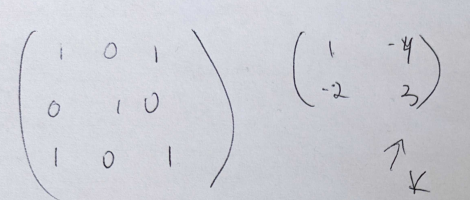

Work out the 2x2 output on paper, then type it in as `by_hand`.

**(b) In code.** Write `conv2d(x, kernel, padding=0, stride=(1, 1))` in NumPy. Pad,
get the output size from the formula, then slide the kernel and fill in each output
pixel. `stride` is a (row, column) pair, the order PyTorch uses. `np.pad(x, p)` puts
`p` zeros on every side of a 2D array.

**(c) A strided example.** Fig. 8 of Ruehle's review,
[*Data science applications to string theory*](https://www.sciencedirect.com/science/article/pii/S0370157319303072):
a 5x6 input and a 3x3 filter, stepping 3 across and 2 down, no padding.

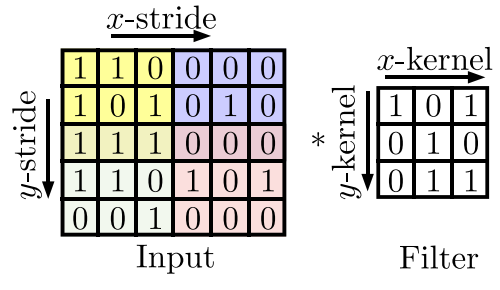

Run your `conv2d` on it and call the result `fig8`. Mind which stride goes first.

**(d) Max pooling.** Write `maxpool2d(x, size=2)`: windows of `size` x `size` that
don't overlap, keeping the largest entry of each. A partial window at the edge gets
dropped, as in PyTorch.

**Known answers.** The checks run PyTorch's own `conv2d` and `MaxPool2d` on the same
inputs and want yours to agree, including on a random input with padding and unequal
strides. There is nothing to look up.

In [ ]:
# GIVEN: the inputs for Problem 1.
hand_input = np.array([[1, 0, 1],
                       [0, 1, 0],
                       [1, 0, 1]])
hand_kernel = np.array([[1, -4],
                        [-2, 3]])

fig8_input = np.array([[1, 1, 0, 0, 0, 0],
                       [1, 0, 1, 0, 1, 0],
                       [1, 1, 1, 0, 0, 0],
                       [1, 1, 0, 1, 0, 1],
                       [0, 0, 1, 0, 0, 0]])
fig8_kernel = np.array([[1, 0, 1],
                        [0, 1, 0],
                        [0, 1, 1]])

pool_input = np.array([[ 3, 2, 0, 0,  0, 0],
                       [-1, 0, 6, 0, 10, 0],
                       [ 2, 3, 4, 0,  0, 0],
                       [ 4, 3, 0, 2,  0, 1],
                       [ 0, 0, 1, 0,  0, 0]])

In [ ]:
# FILL IN (a): your 2x2 answer from paper, as a NumPy array called by_hand.

In [ ]:
# FILL IN (b): conv2d.
def conv2d(x, kernel, padding=0, stride=(1, 1)):
    """Slide kernel across x; each output pixel is the sum of kernel times the window."""
    # FILL IN: pad x with zeros, `padding` of them on every side
    # FILL IN: the kernel's height and width, then the row stride and column stride
    # FILL IN: the output height and width, from the size formula
    out = np.zeros((H_out, W_out))
    # FILL IN: loop over every output pixel (i, j). For each, cut out the window of the
    # padded input that the kernel covers, multiply element by element, and add it up.
    return out

In [ ]:
# FILL IN (c): conv2d on the strided example, saved as fig8.

In [ ]:
# CHECK (given): your hand answer and your conv2d against PyTorch's.
import torch.nn.functional as F


def torch_conv2d(x, kernel, padding=0, stride=(1, 1)):
    t = F.conv2d(torch.tensor(x, dtype=torch.float32)[None, None],
                 torch.tensor(kernel, dtype=torch.float32)[None, None],
                 padding=padding, stride=stride)
    return t[0, 0].numpy()


def agree(mine, ref, what):
    mine = np.asarray(mine, dtype=float)
    assert mine.shape == ref.shape, f"{what}: shape {mine.shape}, but PyTorch gives {ref.shape}"
    assert np.allclose(mine, ref), f"{what}: right shape, wrong numbers"
    print(f"{what}: agrees with PyTorch")


agree(by_hand, torch_conv2d(hand_input, hand_kernel), "(a) your hand answer")
agree(conv2d(hand_input, hand_kernel), torch_conv2d(hand_input, hand_kernel), "(b) conv2d on the hand example")
agree(fig8, torch_conv2d(fig8_input, fig8_kernel, stride=(2, 3)), "(c) fig8")
rng = np.random.default_rng(0)
x_rand, k_rand = rng.normal(size=(7, 9)), rng.normal(size=(3, 2))
agree(conv2d(x_rand, k_rand, padding=1, stride=(2, 1)),
      torch_conv2d(x_rand, k_rand, padding=1, stride=(2, 1)),
      "(b) conv2d on a random 7x9 input, 3x2 kernel, padding 1, stride (2, 1)")
print("PASS: your conv2d is PyTorch's conv2d.")
print()
print("fig8 =")
print(fig8)

In [ ]:
# FILL IN (d): maxpool2d.
def maxpool2d(x, size=2):
    """Non-overlapping size x size windows; keep the largest entry of each."""
    # FILL IN: the output height and width; a partial window at the edge is dropped
    out = np.zeros((H_out, W_out))
    # FILL IN: loop over the output pixels, each one the largest entry in its window
    return out

In [ ]:
# CHECK (given): your maxpool2d against PyTorch's MaxPool2d.
def torch_maxpool2d(x, size=2):
    t = torch.nn.MaxPool2d(size)(torch.tensor(x, dtype=torch.float32)[None, None])
    return t[0, 0].numpy()


agree(maxpool2d(pool_input), torch_maxpool2d(pool_input), "(d) maxpool2d on the 5x6 example")
rng = np.random.default_rng(1)
x_rand = rng.normal(size=(7, 9))
agree(maxpool2d(x_rand, 3), torch_maxpool2d(x_rand, 3), "(d) maxpool2d on a random 7x9 input, 3x3 windows")
print("PASS: your maxpool2d is PyTorch's MaxPool2d.")
print()
print(pool_input)
print("pools to")
print(maxpool2d(pool_input))

## Problem 2 — Spiral or elliptical: a dense network against a CNN

The images are from the Sloan Digital Sky Survey, and the labels are from
[Galaxy Zoo](https://data.galaxyzoo.org), where volunteers classified galaxies by eye
([Lintott et al. 2008](http://adsabs.harvard.edu/abs/2008MNRAS.389.1179L)). We keep
the two confident classes, spiral and elliptical, and leave out the ones the
volunteers called uncertain. The data comes as `GalaxyZoo.zip`, and the first cell
below unzips it the first time you run it.

Build two classifiers, train both the same way, and compare.

1. `ffnn`, dense: `torch.nn.Flatten()`, then `Linear` from 3 x 60 x 60 = 10,800 to 64,
   `ReLU`, `Linear` from 64 to 2.
2. `cnn`: `Conv2d` from 3 channels to 8 with a 5x5 kernel, `ReLU`, `MaxPool2d(2)`;
   `Conv2d` from 8 to 16 with a 5x5 kernel, `ReLU`, `MaxPool2d(2)`; then `Flatten` and
   a `Linear` to 2. The input size of that last `Linear` is yours to work out. Run 60
   through the size formula once for each layer that changes it, then multiply by the
   number of channels.

Two outputs and no Softmax, since `CrossEntropyLoss` applies its own. Training is
given.

**Known answers.** About three quarters of the test galaxies are spirals, so calling
everything a spiral scores 76%. Both networks reach about 95%. The dense one needs
691,394 parameters to get there and the CNN 8,434, about 80 times fewer. The check
wants both above 85%, and the CNN under a tenth the size of the dense one.

The dense network does better than you might expect, and the reason is physics:
ellipticals are old stars and red, spirals are still making young blue ones, so color
alone sorts a lot of them. If you finish early, average the three channels into one so
only the shape is left, and retrain both.

In [ ]:
# GIVEN: the galaxies. The first run unzips GalaxyZoo.zip next to this notebook;
# after that the folder is there and the unzip is skipped.
import ast, os, zipfile
from PIL import Image

if not os.path.isdir("GalaxyZoo"):
    with zipfile.ZipFile("GalaxyZoo.zip") as z:
        z.extractall(".")

# One row per galaxy: SDSS object id, then one-hot (spiral, elliptical, uncertain).
rows = ast.literal_eval(open("GalaxyZoo/training_data.txt").read())
rows = [r for r in rows if r[3] == 0]          # drop "uncertain"
classes = ["spiral", "elliptical"]

# 120x120 color jpgs, halved to 60x60 so training takes seconds, not minutes.
images = np.stack([np.asarray(Image.open(f"GalaxyZoo/{r[0]}.jpg").reduce(2)) for r in rows])
X = torch.tensor(images, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0   # (N, 3, 60, 60)
y = torch.tensor([0 if r[1] == 1 else 1 for r in rows])                       # 0 spiral, 1 elliptical

# 80/20 train/test split, the same for everyone; scale with the training set's stats.
perm = torch.randperm(len(X), generator=torch.Generator().manual_seed(0))
test_idx, train_idx = perm[:len(X) // 5], perm[len(X) // 5:]
mean, std = X[train_idx].mean(), X[train_idx].std()
x_train, y_train = (X[train_idx] - mean) / std, y[train_idx]
x_test, y_test = (X[test_idx] - mean) / std, y[test_idx]
test_images = images[test_idx.numpy()]        # unscaled, for plotting
print("train:", tuple(x_train.shape), "  test:", tuple(x_test.shape))
print("spirals in the test set:", f"{100 * (y_test == 0).float().mean().item():.0f}%")

fig, axes = plt.subplots(1, 8, figsize=(11, 1.9))
for k, ax in enumerate(axes):
    ax.imshow(test_images[k])
    ax.set_title(classes[int(y_test[k])], fontsize=9)
    ax.axis("off")
plt.show()

In [ ]:
# GIVEN: last week's loop, on shuffled minibatches of 64, with Adam. It returns the
# test accuracy after every epoch so you can watch the two networks learn.
def accuracy(model, x, y):
    with torch.no_grad():
        return (model(x).argmax(1) == y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def train(model, n_epochs=15, batch_size=64, lr=1e-3):
    assert n_params(model) > 0, "this model has no layers with weights in it yet"
    torch.manual_seed(0)
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(n_epochs):
        order = torch.randperm(len(x_train))
        for start in range(0, len(x_train), batch_size):
            batch = order[start:start + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(x_train[batch]), y_train[batch])
            loss.backward()
            optimizer.step()
        history.append(accuracy(model, x_test, y_test))
        print(f"epoch {epoch + 1:2d}: test accuracy {100 * history[-1]:.1f}%")
    return history

In [ ]:
# FILL IN: the dense network, four layers inside Sequential, as described above.
torch.manual_seed(0)       # GIVEN: same initialization for everyone
ffnn = torch.nn.Sequential(
)
print(ffnn)
print("parameters:", n_params(ffnn))
ffnn_history = train(ffnn)

In [ ]:
# FILL IN: the CNN, as described above.
torch.manual_seed(0)       # GIVEN: same initialization for everyone
cnn = torch.nn.Sequential(
    # FILL IN: first block, conv then activation then pool
    # FILL IN: second block, the same three
    # FILL IN: flatten, then one Linear to the two class scores
)
print(cnn)
print("parameters:", n_params(cnn))
cnn_history = train(cnn)

In [ ]:
# CHECK (given): the two networks side by side.
assert not any(isinstance(m, torch.nn.Conv2d) for m in ffnn), "ffnn should be dense only, no Conv2d"
assert any(isinstance(m, torch.nn.Conv2d) for m in cnn), "cnn has no Conv2d layer"
assert any(isinstance(m, torch.nn.MaxPool2d) for m in cnn), "cnn has no MaxPool2d layer"

baseline = (y_test == 0).float().mean().item()
ffnn_acc, cnn_acc = accuracy(ffnn, x_test, y_test), accuracy(cnn, x_test, y_test)
print(f"{'':22s}{'parameters':>12s}{'train':>9s}{'test':>8s}")
print(f"{'always say spiral':22s}{0:12,d}{'':>9s}{100 * baseline:7.1f}%")
for name, m, a in [("dense", ffnn, ffnn_acc), ("CNN", cnn, cnn_acc)]:
    print(f"{name:22s}{n_params(m):12,d}{100 * accuracy(m, x_train, y_train):8.1f}%{100 * a:7.1f}%")
print(f"the CNN uses {n_params(ffnn) / n_params(cnn):.0f}x fewer parameters")
print()

assert ffnn_acc > 0.85, f"the dense network should beat 85% on the test set, got {100 * ffnn_acc:.1f}%"
assert cnn_acc > 0.85, f"the CNN should beat 85% on the test set, got {100 * cnn_acc:.1f}%"
assert n_params(cnn) < n_params(ffnn) / 10, "the CNN should be under a tenth the size of the dense network"
print("PASS: same job, a fraction of the parameters.")

epochs = np.arange(1, len(cnn_history) + 1)
plt.figure(figsize=(5, 3))
plt.plot(epochs, 100 * np.array(ffnn_history), "o-", label=f"dense, {n_params(ffnn):,} params")
plt.plot(epochs, 100 * np.array(cnn_history), "s-", label=f"CNN, {n_params(cnn):,} params")
plt.axhline(100 * baseline, ls=":", c="r", label="always say spiral")
plt.xlabel("epoch")
plt.ylabel("test accuracy (%)")
plt.legend()
plt.show()

with torch.no_grad():
    pred = cnn(x_test[:10]).argmax(1)
fig, axes = plt.subplots(1, 10, figsize=(12, 1.9))
for k, ax in enumerate(axes):
    ax.imshow(test_images[k])
    ax.set_title(classes[int(pred[k])], fontsize=9, color="k" if pred[k] == y_test[k] else "r")
    ax.axis("off")
plt.suptitle("the CNN on ten test galaxies (red = wrong)", y=1.1)
plt.show()